<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_%D0%BB%D0%B15_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [38]:
# Імпортуйте необхідні бібліотеки
import numpy as np
import kagglehub
import pandas as pd
import os
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.preprocessing import MinMaxScaler
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error
from prophet import Prophet
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
# Download latest version
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)

100%|██████████| 194k/194k [00:00<00:00, 389kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/yug201/daily-climate-time-series-data-delhi-india/versions/1


In [4]:
# Зчитайте датасет у DataFrame та перегляньте дані
df=pd.read_csv(os.path.join(path, 'kaggel_weather_2013_to_2024.csv'))
df

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3552,3552,11/26/2024,25.8,13.6,18.6,25.8,13.6,18.6,65.9,0.0,...,24,48,1700.22,896.24,1225.74,1700.22,896.24,1225.74,12.2,242.171864
3553,3553,11/27/2024,26.2,12.5,18.4,26.2,12.5,18.4,61.0,0.0,...,24,48,1598.20,762.50,1122.40,1598.20,762.50,1122.40,13.7,236.769595
3554,3554,11/28/2024,25.8,11.5,17.9,25.8,11.5,17.9,63.1,0.0,...,24,48,1627.98,725.65,1129.49,1627.98,725.65,1129.49,14.3,243.117035
3555,3555,11/29/2024,25.0,10.6,18.0,25.0,10.6,18.0,60.0,0.0,...,24,48,1500.00,636.00,1080.00,1500.00,636.00,1080.00,14.4,237.638344


Підготовка даних

In [5]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
df['DATE']=pd.to_datetime(df['DATE'])

df=df.sort_values('DATE')

df=df.drop(columns=['Unnamed: 0'])

df=df.set_index('DATE')

df.head()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [6]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [7]:
# Перевірте наявність пропущених значень
df.isnull().sum()

,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Графік температури

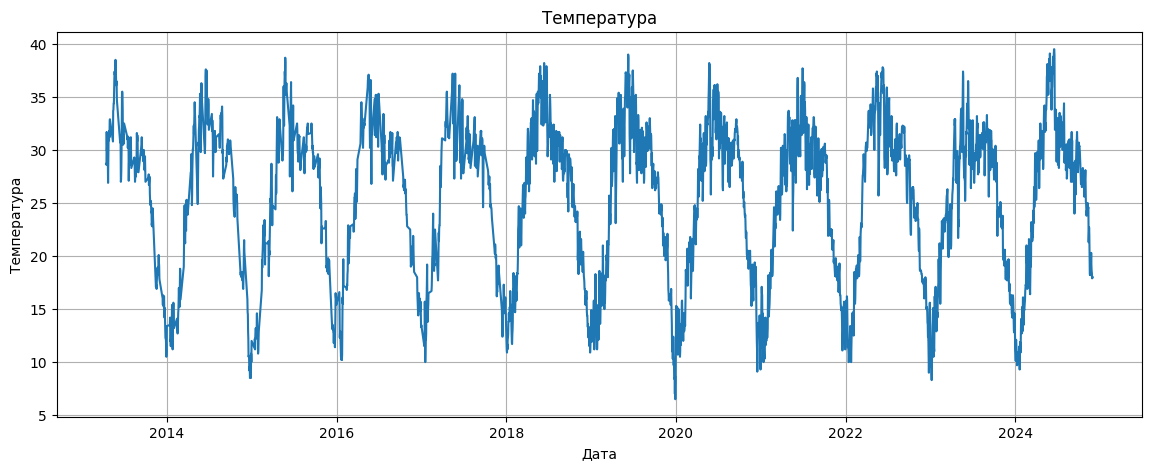

In [8]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14,5))
plt.plot(df['temp'])
plt.title('Температура')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.grid()
plt.show()

Ковзне середнє

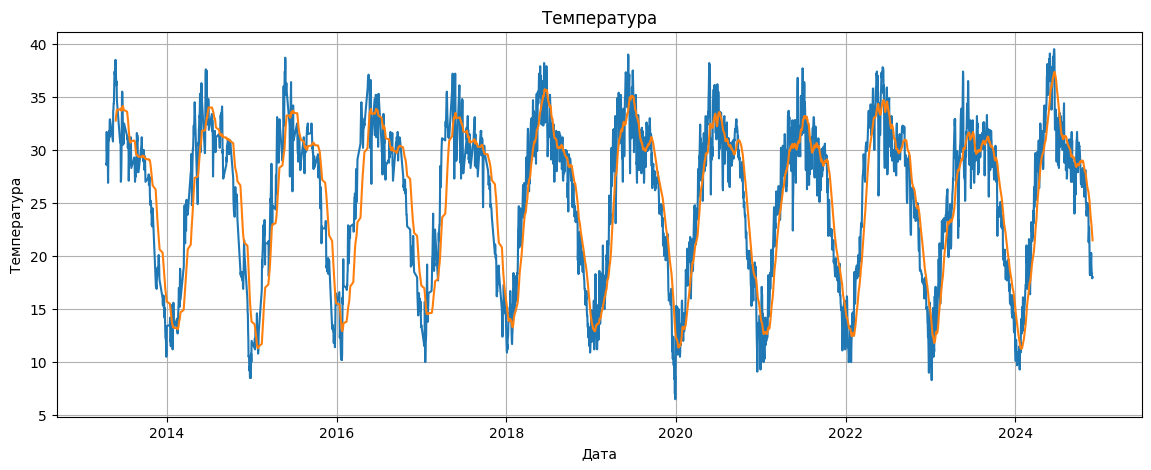

In [9]:
# Обчисліть та візуалізуйте ковзне середнє температури
df['rolling_mean']=df['temp'].rolling(window=30).mean()

plt.figure(figsize=(14,5))
plt.plot(df['temp'])
plt.plot(df['rolling_mean'])
plt.title('Температура')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.grid()
plt.show()

Розподіл температури

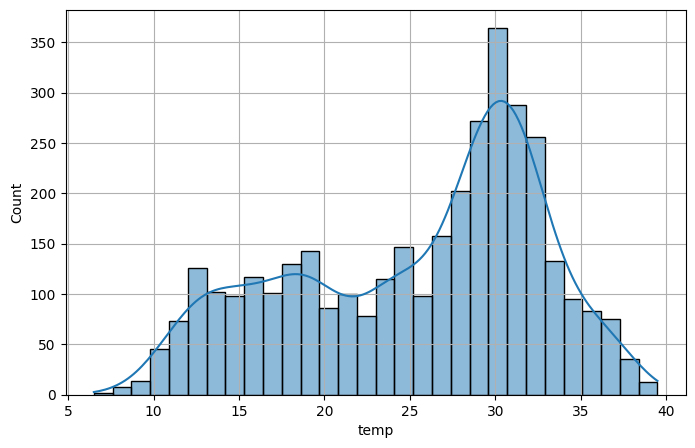

In [10]:
# Побудуйте гістограму розподілу температури
import seaborn as sns
plt.figure(figsize=(8,5))
sns.histplot(df['temp'], bins=30, kde=True)
plt.grid()
plt.show()

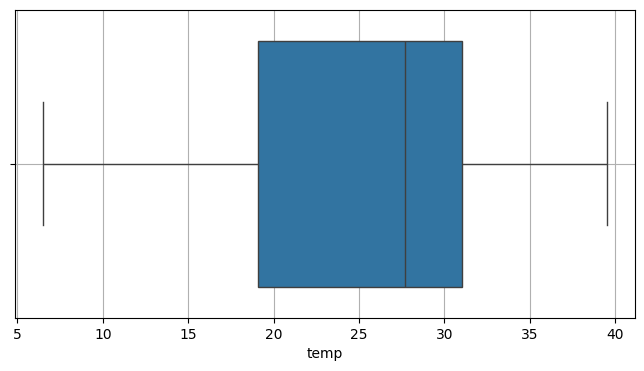

In [11]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8,4))
sns.boxplot(x=df['temp'])
plt.grid()
plt.show()


Аналіз автокореляції
ACF

PACF

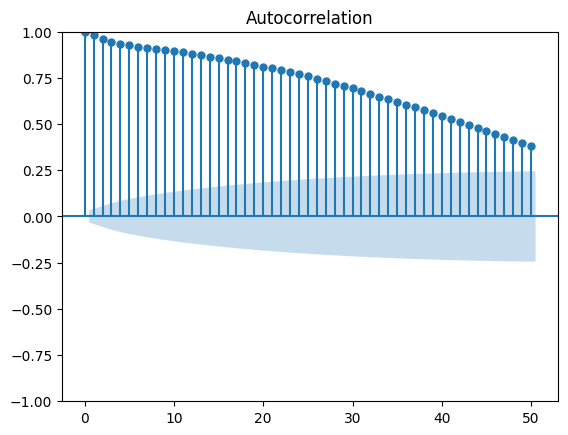

In [12]:
# Побудуйте графік автокореляційної функції (ACF)
plot_acf(df['temp'], lags=50)
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

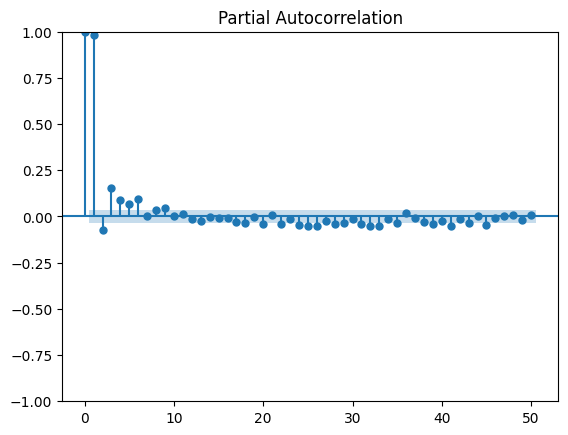

In [13]:
# Побудуйте графік часткової автокореляційної функції (PACF)
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(df['temp'], lags=50)
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [14]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
target=df['temp'].copy()
split_index=int(len(target)*0.8)

train=target.iloc[:split_index]
test=target.iloc[split_index:]
print(len(train))
print(len(test))

2845
712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [17]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки


train_arima=train.reset_index(drop=True)
arima_model=ARIMA(train_arima, order=(5,1,2))
arima_fit=arima_model.fit()

arima_forecast=arima_fit.forecast(steps=len(test))
arima_forecast.index=test.index
arima_forecast.head()



,predicted_mean
DATE,
2022-12-20,14.895737
2022-12-21,15.071189
2022-12-22,15.161451
2022-12-23,15.179429
2022-12-24,15.200756


In [18]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 2845
Model:                 ARIMA(5, 1, 2)   Log Likelihood               -4969.050
Date:                Fri, 23 Oct 2026   AIC                           9954.101
Time:                        19:59:23   BIC                          10001.724
Sample:                             0   HQIC                          9971.277
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1810      0.227      0.799      0.424      -0.263       0.625
ar.L2          0.1094      0.205      0.533      0.594      -0.293       0.511
ar.L3         -0.1108      0.049     -2.242      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

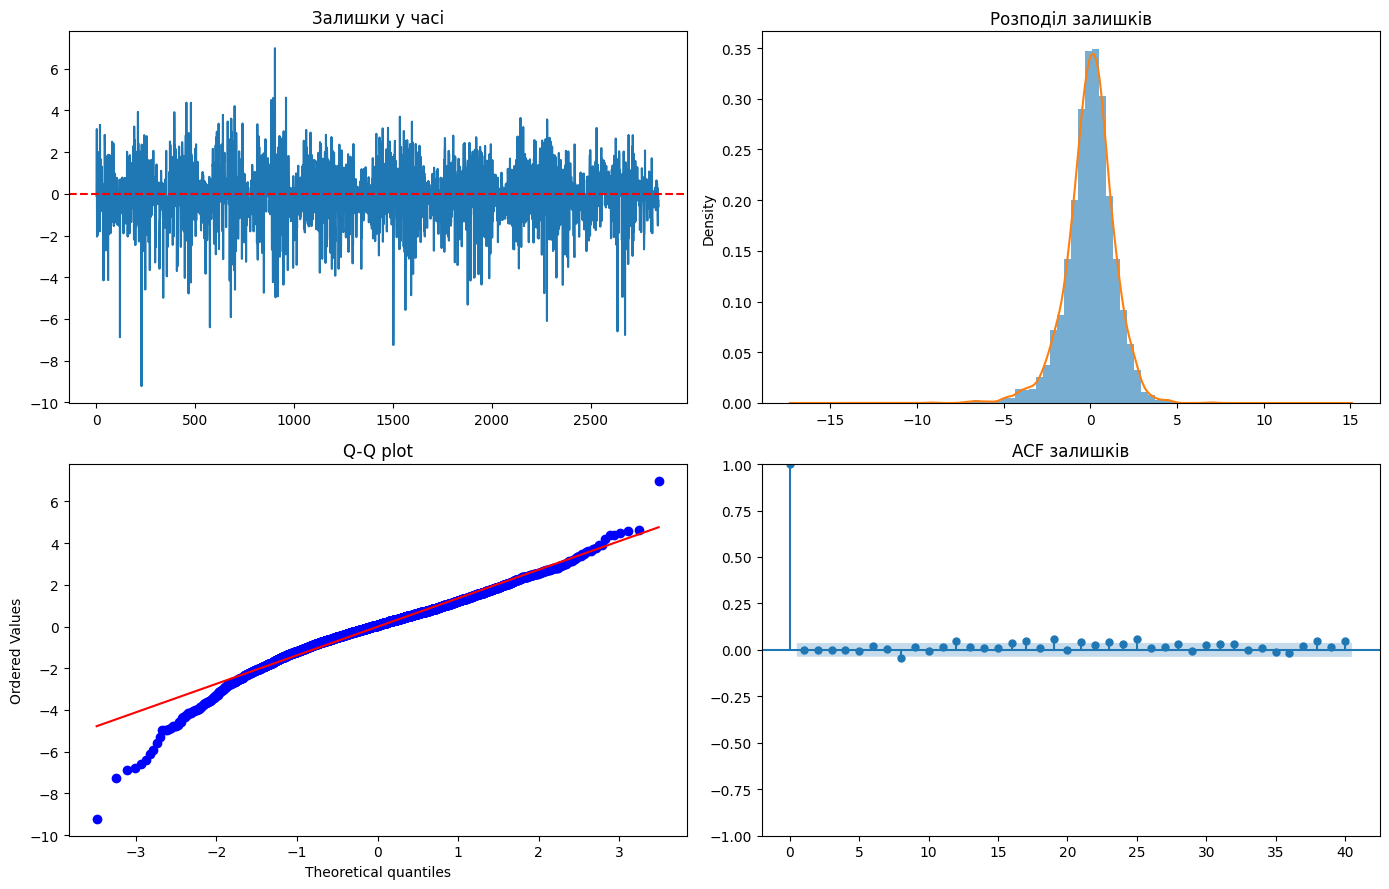

Середнє залишків: -0.007585417373529301
Стандартне відхилення: 1.3888240879200602

Тест Льюнга-Бокса (автокореляція залишків):
      lb_stat  lb_pvalue
10   7.699833   0.658130
20  36.351766   0.013980
30  67.894960   0.000092

Тест Жарка-Бера (нормальність):
statistic=1036.55, p-value=0.0000


In [21]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки


resid = arima_fit.resid
resid = resid.iloc[1:]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(resid)
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_title('Залишки у часі')


resid.plot(kind='hist', bins=40, density=True, alpha=0.6, ax=axes[0, 1])
resid.plot(kind='kde', ax=axes[0, 1])
axes[0, 1].set_title('Розподіл залишків')


stats.probplot(resid, dist='norm', plot=axes[1, 0])
axes[1, 0].set_title('Q-Q plot')


plot_acf(resid, lags=40, ax=axes[1, 1])
axes[1, 1].set_title('ACF залишків')

plt.tight_layout()
plt.show()


print("Середнє залишків:", resid.mean())
print("Стандартне відхилення:", resid.std())

print("\nТест Льюнга-Бокса (автокореляція залишків):")
print(acorr_ljungbox(resid, lags=[10, 20, 30], return_df=True))

print("\nТест Жарка-Бера (нормальність):")
jb_stat, jb_p = stats.jarque_bera(resid)
print(f"statistic={jb_stat:.2f}, p-value={jb_p:.4f}")

In [24]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0   # уникаємо ділення на нуль
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

y_true = test        # замініть 'temp' на свій стовпець, якщо test — DataFrame
y_pred = arima_forecast

arima_mae  = mean_absolute_error(y_true, y_pred)
arima_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
arima_mape = mape(y_true, y_pred)

print(f"ARIMA MAE:  {arima_mae:.3f}")
print(f"ARIMA RMSE: {arima_rmse:.3f}")
print(f"ARIMA MAPE: {arima_mape:.2f}%")

ARIMA MAE:  10.928
ARIMA RMSE: 12.501
ARIMA MAPE: 39.59%


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

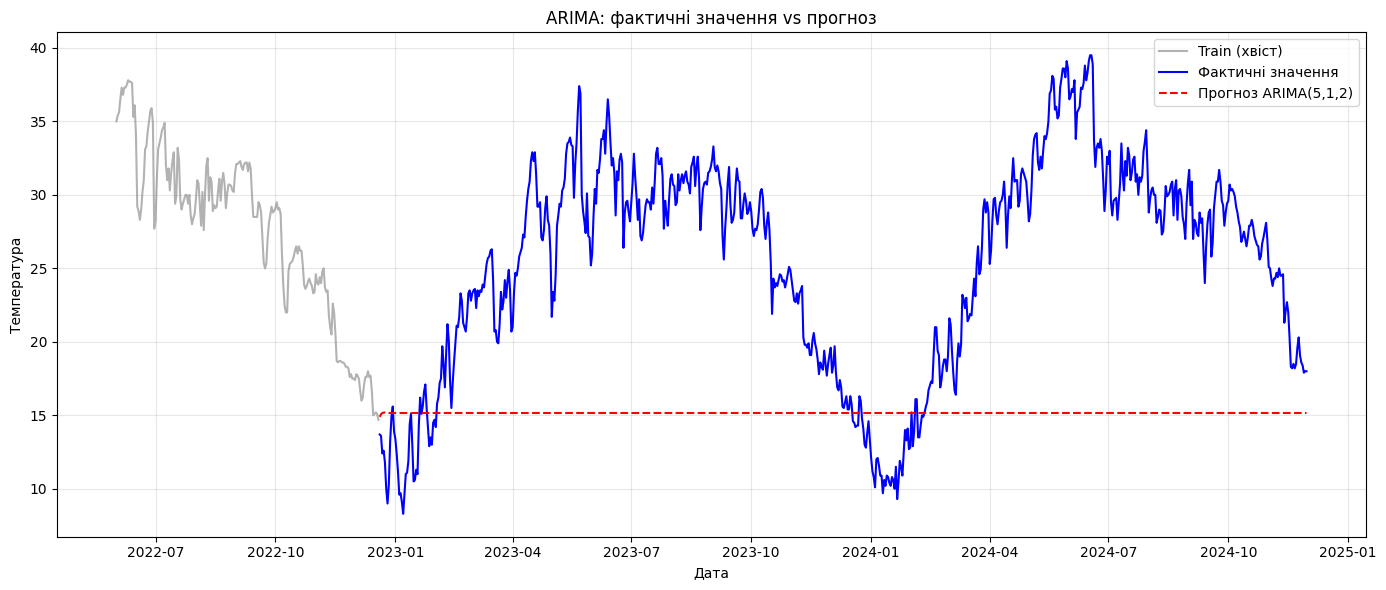

In [25]:
# Підготуйте дані у форматі, необхідному для Prophet


plt.figure(figsize=(14, 6))
plt.plot(train.index[-200:], train.iloc[-200:], label='Train (хвіст)', color='gray', alpha=0.6)


plt.plot(test.index, test, label='Фактичні значення', color='blue')
plt.plot(arima_forecast.index, arima_forecast, label='Прогноз ARIMA(5,1,2)', color='red', linestyle='--')

plt.title('ARIMA: фактичні значення vs прогноз')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# Створіть та навчіть модель Prophet
train_prophet = train.reset_index()
train_prophet.columns = ['ds', 'y']


prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)
prophet_model.fit(train_prophet)

Прогноз

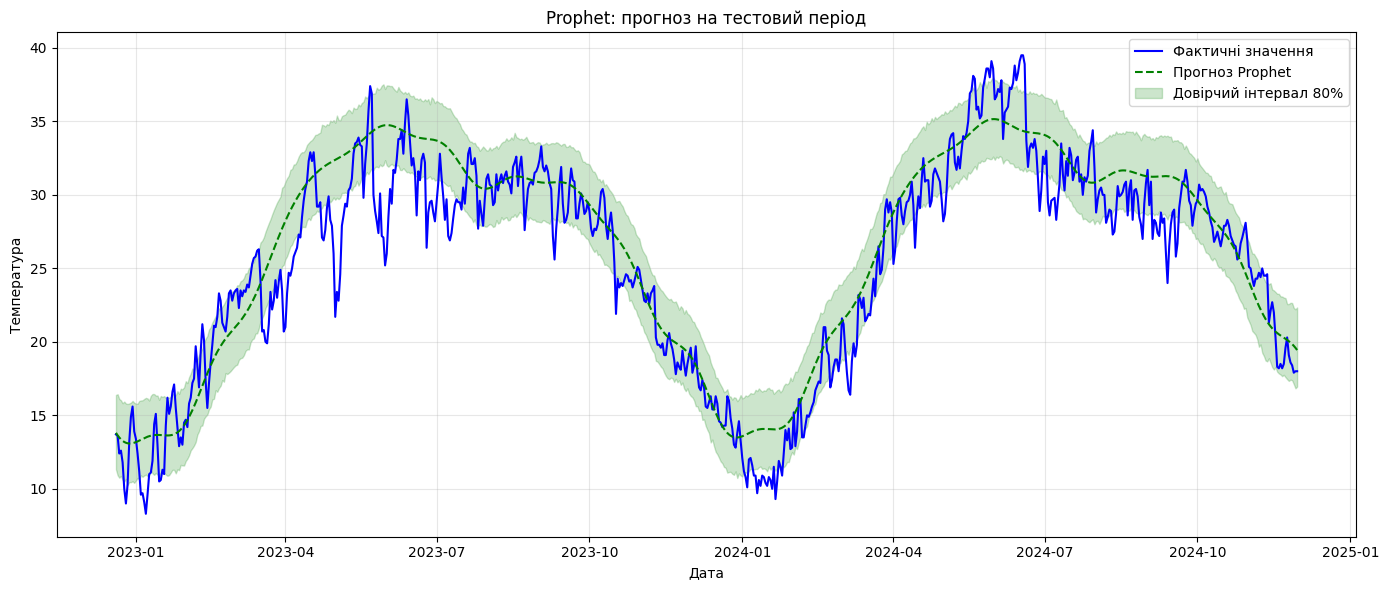

In [29]:
# Побудуйте прогноз Prophet для тестового періоду
future = pd.DataFrame({'ds': test.index})
prophet_forecast = prophet_model.predict(future)

prophet_pred = pd.Series(prophet_forecast['yhat'].values, index=test.index)

plt.figure(figsize=(14, 6))

plt.plot(test.index, test, label='Фактичні значення', color='blue')
plt.plot(prophet_pred.index, prophet_pred, label='Прогноз Prophet', color='green', linestyle='--')

plt.fill_between(
    test.index,
    prophet_forecast['yhat_lower'].values,
    prophet_forecast['yhat_upper'].values,
    color='green', alpha=0.2, label='Довірчий інтервал 80%'
)

plt.title('Prophet: прогноз на тестовий період')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# Обчисліть MAE, RMSE, MAPE для Prophet


prophet_mae  = mean_absolute_error(test, prophet_pred)
prophet_rmse = np.sqrt(mean_squared_error(test, prophet_pred))
prophet_mape = mape(test, prophet_pred)   # функція mape визначена раніше

print(f"Prophet MAE:  {prophet_mae:.3f}")
print(f"Prophet RMSE: {prophet_rmse:.3f}")
print(f"Prophet MAPE: {prophet_mape:.2f}%")

Prophet MAE:  2.010
Prophet RMSE: 2.596
Prophet MAPE: 9.06%


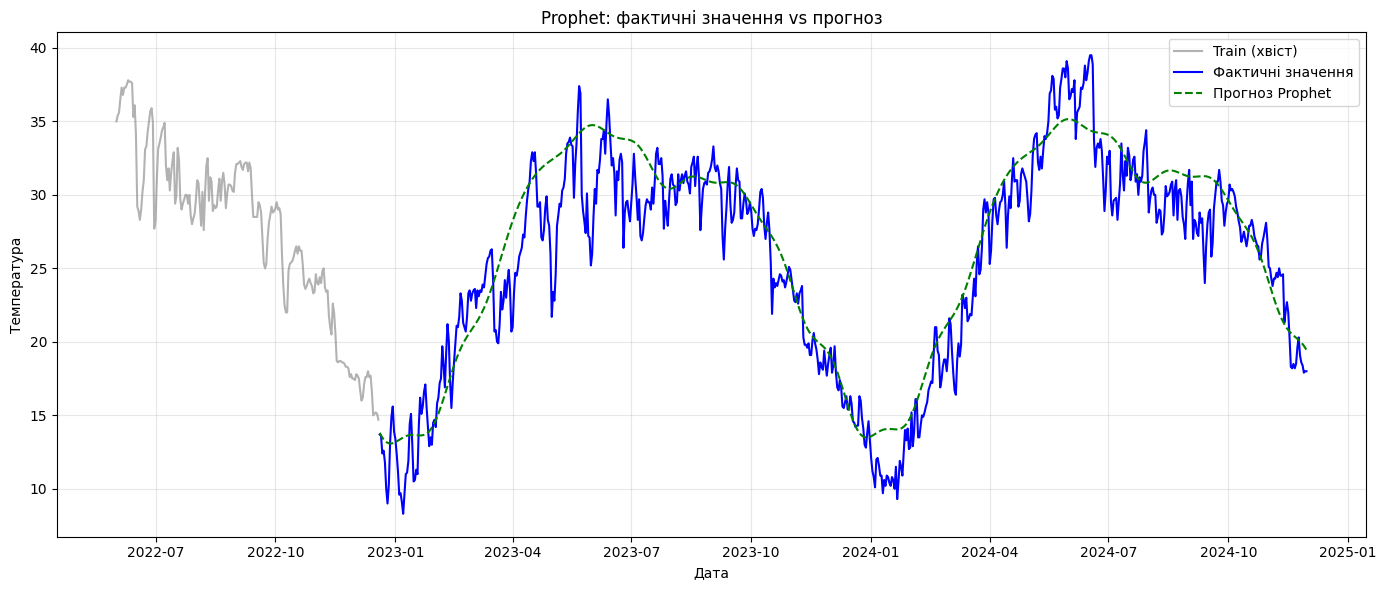

In [32]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 6))

# Хвіст навчальної вибірки для контексту
plt.plot(train.index[-200:], train.iloc[-200:], label='Train (хвіст)', color='gray', alpha=0.6)

# Фактичні значення та прогноз Prophet
plt.plot(test.index, test, label='Фактичні значення', color='blue')
plt.plot(prophet_pred.index, prophet_pred, label='Прогноз Prophet', color='green', linestyle='--')

plt.title('Prophet: фактичні значення vs прогноз')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

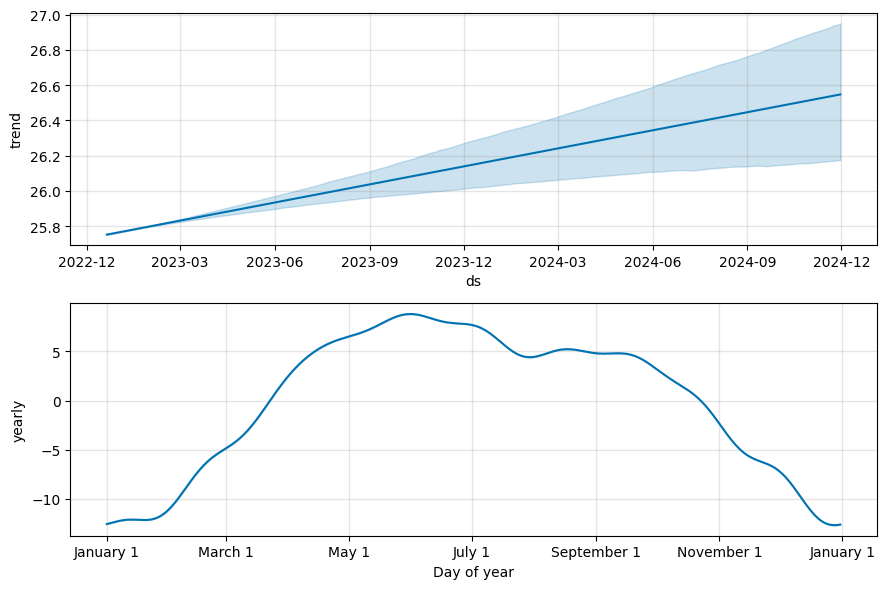

In [45]:
# Побудуйте компоненти моделі Prophet

future = pd.DataFrame({'ds': test.index})
prophet_forecast = prophet_model.predict(future)

fig = prophet_model.plot_components(prophet_forecast)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [60]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
full_series = pd.concat([train, test])


scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train.values.reshape(-1, 1))

full_scaled = scaler.transform(full_series.values.reshape(-1, 1))

def create_sequences(data, window_size):
    X, y = [], []
    for i in range(window_size, len(data)):
        X.append(data[i - window_size:i, 0])
        y.append(data[i, 0])
    X, y = np.array(X), np.array(y)
    return X.reshape(X.shape[0], X.shape[1], 1), y

window_size = 30

X, y = create_sequences(full_scaled, window_size)
print("X:", X.shape, "y:", y.shape)

X: (3527, 30, 1) y: (3527,)


In [66]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=len(test), shuffle=False
)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "y_test: ", y_test.shape)
print(len(X_test) == len(test))   # має бути True

X_train: (2815, 30, 1) y_train: (2815,)
X_test:  (712, 30, 1) y_test:  (712,)
True


In [67]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
lstm_model = Sequential([
    Input(shape=(window_size, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
lstm_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [68]:
# Навчіть LSTM-модель
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,   # беруться останні 10% train, без перемішування
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0367 - mae: 0.1390 - val_loss: 0.0059 - val_mae: 0.0629
Epoch 2/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0101 - mae: 0.0800 - val_loss: 0.0105 - val_mae: 0.0863
Epoch 3/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0087 - mae: 0.0728 - val_loss: 0.0058 - val_mae: 0.0616
Epoch 4/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0073 - mae: 0.0668 - val_loss: 0.0109 - val_mae: 0.0891
Epoch 5/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0070 - mae: 0.0660 - val_loss: 0.0066 - val_mae: 0.0656
Epoch 6/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0062 - mae: 0.0617 - val_loss: 0.0080 - val_mae: 0.0747
Epoch 7/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0064 - mae: 0.0622 - val_loss: 0.0071 - val_mae: 0.0692
Epoch 8/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0056 - mae: 0.0589 - val_loss: 0.0057 - val_mae: 0.0605
Epoch 9/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0

In [69]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,573 (349.90 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 59,716 (233.27 KB)

In [70]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування

lstm_pred_scaled = lstm_model.predict(X_test)


lstm_pred = scaler.inverse_transform(lstm_pred_scaled).flatten()
lstm_pred = pd.Series(lstm_pred, index=test.index)

y_test_real = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_test_real = pd.Series(y_test_real, index=test.index)

print(lstm_pred.head())
print("Довжини:", len(lstm_pred), len(test))

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
DATE
2022-12-20    15.976299
2022-12-21    15.596153
2022-12-22    15.201479
2022-12-23    14.726341
2022-12-24    14.262647
dtype: float32
Довжини: 712 712


In [72]:
# Сформуйте часові мітки для тестового прогнозу LSTM

lstm_index = test.index

print(lstm_index[:3])

DatetimeIndex(['2022-12-20', '2022-12-21', '2022-12-22'], dtype='datetime64[ns]', name='DATE', freq=None)


In [73]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_mae  = mean_absolute_error(y_test_real, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_test_real, lstm_pred))
lstm_mape = mape(y_test_real, lstm_pred)

print(f"LSTM MAE:  {lstm_mae:.3f}")
print(f"LSTM RMSE: {lstm_rmse:.3f}")
print(f"LSTM MAPE: {lstm_mape:.2f}%")

LSTM MAE:  1.623
LSTM RMSE: 2.037
LSTM MAPE: 6.98%


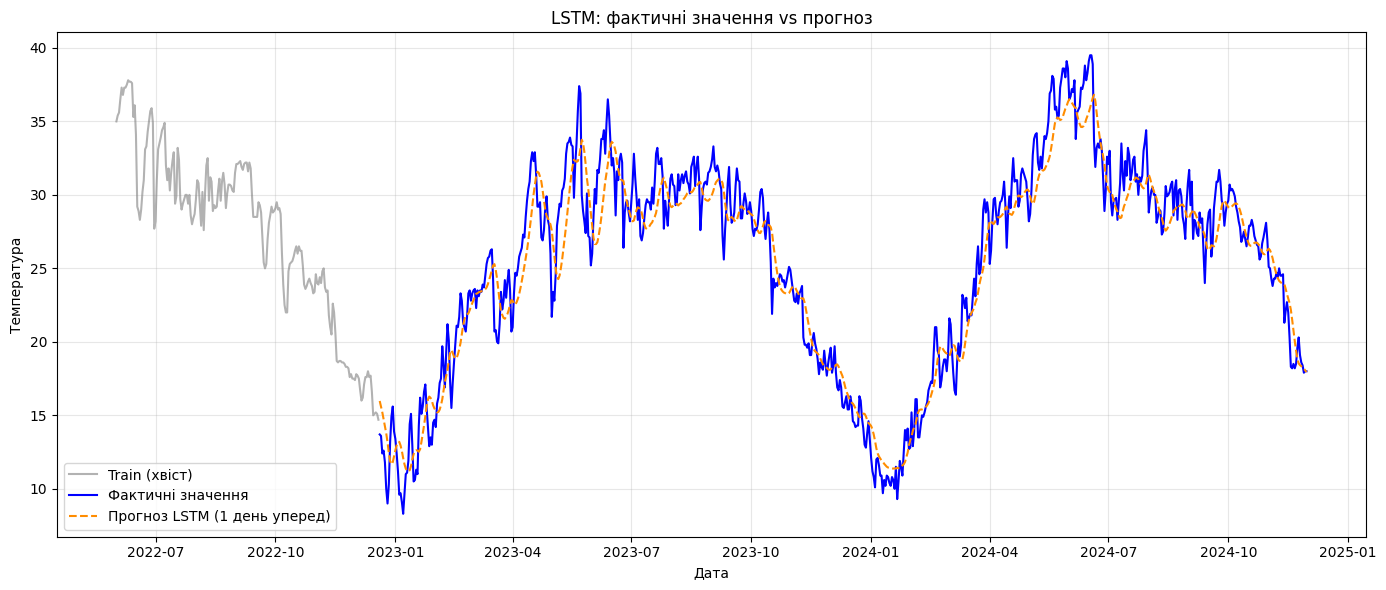

In [75]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 6))


plt.plot(train.index[-200:], train.iloc[-200:], label='Train (хвіст)', color='gray', alpha=0.6)


plt.plot(y_test_real.index, y_test_real, label='Фактичні значення', color='blue')
plt.plot(lstm_pred.index, lstm_pred, label='Прогноз LSTM (1 день уперед)', color='darkorange', linestyle='--')

plt.title('LSTM: фактичні значення vs прогноз')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Порівняння моделей

In [77]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
# Підсумкова таблиця метрик
results = pd.DataFrame({
    'Модель':  ['ARIMA(5,1,2)', 'Prophet', 'LSTM'],
    'MAE':     [arima_mae,  prophet_mae,  lstm_mae],
    'RMSE':    [arima_rmse, prophet_rmse, lstm_rmse],
    'MAPE, %': [arima_mape, prophet_mape, lstm_mape]
}).round(3)

results = results.set_index('Модель')
display(results)

# Найкраща модель за кожною метрикою
print("\nНайкраща модель за метрикою:")
print(results.idxmin())

,MAE,RMSE,"MAPE, %"
Модель,,,
"ARIMA(5,1,2)",10.928,12.501,39.592
Prophet,2.010,2.596,9.056
LSTM,1.623,2.037,6.979



Найкраща модель за метрикою:
MAE        LSTM
RMSE       LSTM
MAPE, %    LSTM
dtype: object


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


Під час виконання лабораторнрї роботи ми провели аналіз роботи моделей Arima, Propeht та LSTM. У результаті роботи було виявлено, що  модель LSTM є найкращою з трьох серед усіх моделей по MAE, RMSE, MAPE. На другому місті опинилась Prophet, тоді як Аріма показала замітно гірший результат